<a href="https://colab.research.google.com/github/rudrapratapchavan011005/LocalRepo/blob/main/HousePricePrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)



from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [42]:
from google.colab import files
uploaded = files.upload()

Saving Housing.csv to Housing (1).csv


In [43]:
df = pd.read_csv("Housing.csv")

In [44]:
print("First Five Records:")

print(df.head())


print("\nDataset Shape:")
print(df.shape)


print("\nDataset Information:")
df.info()


print("\nMissing Values:")
print(df.isnull().sum())


print("\nDuplicate Records:")
print(df.duplicated().sum())


print("\nStatistical Summary:")
print(df.describe())


print("\nColumn Names:")
print(df.columns.tolist())


First Five Records:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Dataset Shape:
(545, 13)

Dataset Information:
<class 'pandas.core.frame.DataF

In [45]:

df.columns = df.columns.str.strip().str.lower()

df = df.drop_duplicates()

df["price"] = pd.to_numeric(df["price"], errors="coerce")

df = df.dropna(subset=["price"])


X = df.drop(columns=["price"])
y = df["price"]

num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()


num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Original dataset shape:", df.shape)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Input features:", X.columns.tolist())
print("Target variable: price")

print("\nPreprocessing setup completed successfully.")


Original dataset shape: (545, 13)
Training data shape: (436, 12)
Testing data shape: (109, 12)
Input features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
Target variable: price

Preprocessing setup completed successfully.


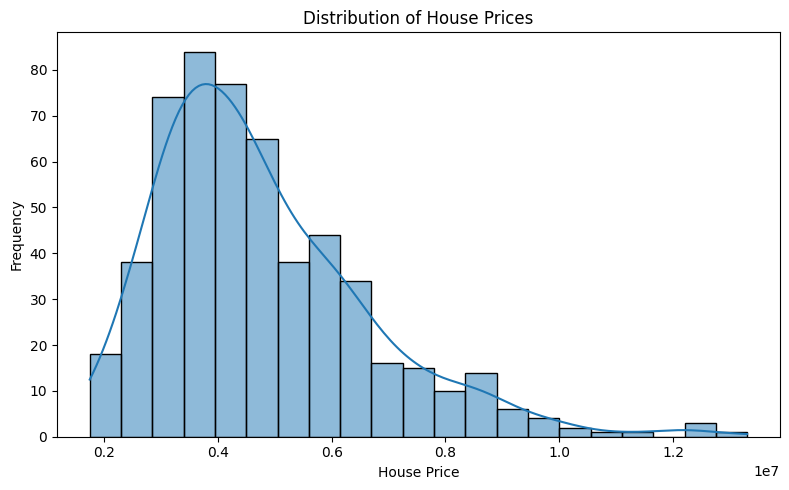

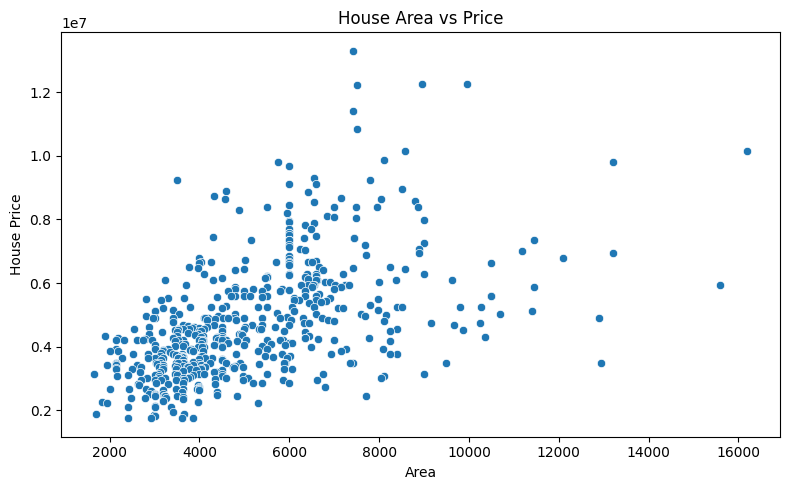

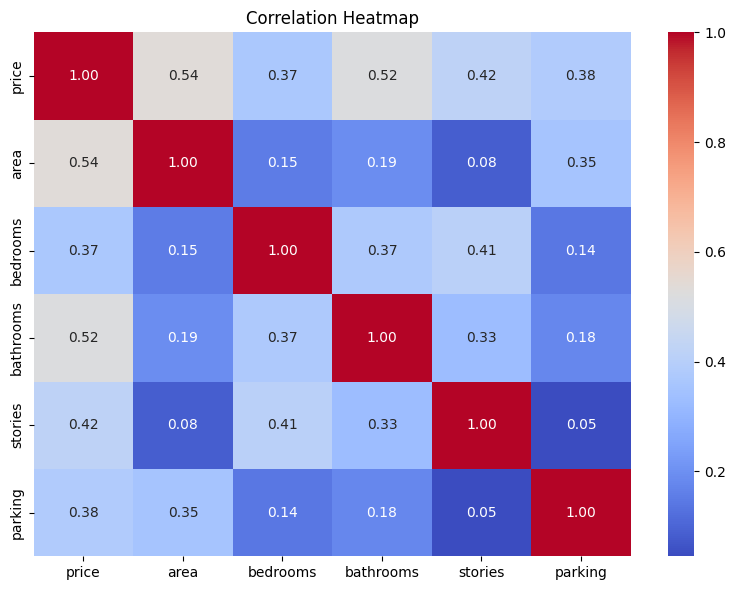

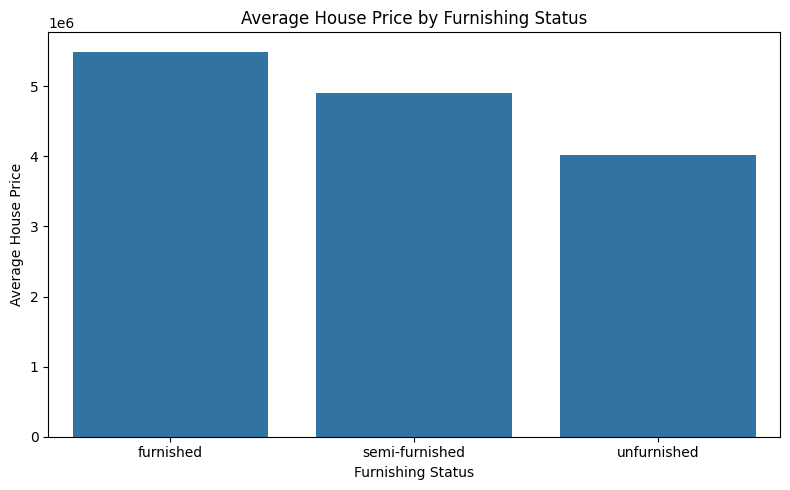


EDA completed successfully.


In [46]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path




plt.figure(figsize=(8, 5))
sns.histplot(df["price"].dropna(), kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("outputs/price_distribution.png")
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="area", y="price")
plt.title("House Area vs Price")
plt.xlabel("Area")
plt.ylabel("House Price")
plt.tight_layout()
plt.savefig("outputs/area_vs_price.png")
plt.show()

numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png")
plt.show()

if "furnishingstatus" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.barplot(data=df, x="furnishingstatus", y="price", errorbar=None)
    plt.title("Average House Price by Furnishing Status")
    plt.xlabel("Furnishing Status")
    plt.ylabel("Average House Price")
    plt.tight_layout()
    plt.savefig("outputs/furnishing_vs_price.png")
    plt.show()

print("\nEDA completed successfully.")

In [47]:

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df = df.dropna(subset=["price"])

X = df.drop(columns=["price"])
y = df["price"]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(
    exclude="number"
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_transformed = preprocessor.fit_transform(X)

print("Original features:", X.shape[1])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Transformed feature shape:", X_transformed.shape)

print("\nFeature engineering completed.")


Original features: 12
Numerical features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
Transformed feature shape: (545, 20)

Feature engineering completed.


In [48]:
if {"bedrooms", "bathrooms"}.issubset(df.columns):
    df["total_rooms"] = df["bedrooms"] + df["bathrooms"]

print(df[["bedrooms", "bathrooms", "total_rooms"]].head())

   bedrooms  bathrooms  total_rooms
0         4          2            6
1         4          4            8
2         3          2            5
3         4          2            6
4         4          1            5


In [49]:

Path("models").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)


df = df.drop_duplicates()
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df = df.dropna(subset=["price"])

X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    )
}

results = []
trained_models = {}

for name, algorithm in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE")

results_df.to_csv("outputs/model_comparison.csv", index=False)

print("\nModel Comparison:")
print(results_df.to_string(index=False))

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

joblib.dump(best_model, "models/house_price_pipeline.joblib")

print("\nBest Model:", best_name)
print("Saved to models/house_price_pipeline.joblib")



Model: Linear Regression
MAE: 970043.4
RMSE: 1324506.96
R2 Score: 0.6529

Model: Ridge Regression
MAE: 970728.61
RMSE: 1325423.31
R2 Score: 0.6524

Model: Random Forest
MAE: 1078154.97
RMSE: 1447998.44
R2 Score: 0.5852

Model: Extra Trees
MAE: 1035341.42
RMSE: 1418209.36
R2 Score: 0.6021

Model Comparison:
            Model          MAE         RMSE  R2 Score
Linear Regression 9.700434e+05 1.324507e+06  0.652924
 Ridge Regression 9.707286e+05 1.325423e+06  0.652444
      Extra Trees 1.035341e+06 1.418209e+06  0.602079
    Random Forest 1.078155e+06 1.447998e+06  0.585187

Best Model: Linear Regression
Saved to models/house_price_pipeline.joblib


In [50]:

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df = df.dropna(subset=["price"])

X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = joblib.load("models/house_price_pipeline.joblib")

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

results.to_csv("outputs/test_predictions.csv", index=False)
print("\nPredictions saved to outputs/test_predictions.csv")


MODEL EVALUATION
----------------
MAE: 970043.4
MSE: 1754318687330.67
RMSE: 1324506.96
R2 Score: 0.6529

Predictions saved to outputs/test_predictions.csv


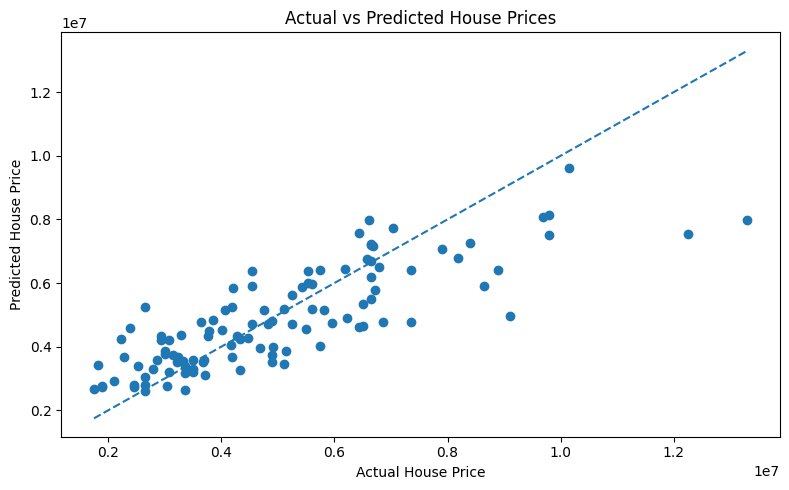

In [51]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)

# Reference line for perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.savefig("outputs/actual_vs_predicted.png")
plt.show()
